In [1]:
#project title : a statistical arbitrage/pairs trading strategy with a full backtesting engine 

In [2]:
import yfinance as yf 
import pandas as pd 
import numpy as np 
from statsmodels.tsa.stattools import coint , adfuller
import itertools as it 
from statsmodels.regression.linear_model import OLS
from statsmodels.tools import add_constant 
import matplotlib.pyplot as plt

In [3]:
# FMCG stocks  
tickers = [ 'HINDUNILVR.NS', 'ITC.NS', 'NESTLEIND.NS', 'BRITANNIA.NS', 'DABUR.NS', 'MARICO.NS', 'COLPAL.NS', 'GODREJCP.NS','EMAMILTD.NS', 'TATACONSUM.NS']

In [4]:
closed_df = pd.DataFrame()
closed_df_test = pd.DataFrame()
split_date = "2024-06-01"

for ticker in tickers:
    data = yf.download(ticker, start='2021-06-01', end='2026-06-01')
    test = data.loc[split_date:] 
    closed_df_test[ticker] = test['Close']
    train = data.loc[:"2024-05-31"]
    closed_df[ticker]= train['Close']

print ( closed_df.head() )

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

            HINDUNILVR.NS      ITC.NS  NESTLEIND.NS  BRITANNIA.NS    DABUR.NS  \
2021-06-01    2146.868408  164.723022    840.023376   3192.679199  502.779327   
2021-06-02    2147.323242  159.940155    835.056519   3219.078613  498.285614   
2021-06-03    2151.374756  159.978394    841.958008   3238.530518  506.289978   
2021-06-04    2132.075684  159.748825    824.333069   3232.092773  509.332550   
2021-06-07    2129.571777  161.815018    829.335327   3281.463867  513.498596   

             MARICO.NS    COLPAL.NS  GODREJCP.NS  EMAMILTD.NS  TATACONSUM.NS  
2021-06-01  450.453247  1528.324097   806.524414   463.924164     635.153992  
2021-06-02  460.105103  1531.668335   807.996765   482.435486     642.547241  
2021-06-03  465.212189  1528.859009   821.058105   501.495209     648.700378  
2021-06-04  456.263123  1513.030029   809.849060   492.353943     655.330505  
2021-06-07  458.512085  1525.470459   806.571960   488.880188     667.732178  


In [5]:
#ADF test on stock prices to check for stationarity

non_stationary_tickers = []

for ticker in tickers:
    series = closed_df[ticker].dropna()

    ADF_test = adfuller(series)

    if ADF_test[1] >= 0.05:
        non_stationary_tickers.append(ticker)

tickers = non_stationary_tickers

In [6]:
# data cleaning to remove Nans and align the dates of the stocks 
# Cointegration Analysis 
results = []
for stock_a, stock_b in it.combinations(tickers, 2): #pairs 2 unique pairs from the provided list 
    pair = closed_df[[stock_a, stock_b]].dropna()
    series_a = pair[stock_a]
    series_b = pair[stock_b]
    if (len(series_a) == len(series_b)) and (series_a.index == series_b.index).all():
        score, pvalue, crit_value = coint(series_a, series_b)  # check for cointegration
        if pvalue < 0.05:  # if p-value is less than 0.05, we can reject the null hypothesis of no cointegration with 95% confidence
           results.append((stock_a, stock_b, pvalue))

results.sort(key=lambda x: x[2])  # sort by p-value
print (results) 

[('COLPAL.NS', 'TATACONSUM.NS', np.float64(0.015861224332933212)), ('MARICO.NS', 'EMAMILTD.NS', np.float64(0.03453932117010649)), ('MARICO.NS', 'COLPAL.NS', np.float64(0.040551083795435656))]


In [7]:
#functions for calculating the hedge ratio using OLS regression and z-score of the spread between two stocks 

def regression(series_a, series_b):
    series_a = add_constant(series_a)
    model = OLS(series_b, series_a).fit()
    return model.params.iloc[1]  # return the hedge ratio (slope of the regression line)

def z_score(series, window=30):
    rolling_mean = series.rolling(window).mean()
    rolling_std  = series.rolling(window).std()
    return (series - rolling_mean) / rolling_std 



In [8]:
def generate_signals(zscore, entry=2.0, exit=0.5 , stop = 4.0 ):
    signal = pd.Series(index=zscore.index, dtype=float) 
    position = 0  

    for date, z in zscore.items(): 
        if position == 0:
            if z > entry:
                position = -1   # shorting the spread 
            elif z < -entry:
                position = 1    # longing the spread
        elif position == 1:
            if z > -exit:       # spread normalised, exit
                position = 0
            elif z < -stop:     # stop-loss
                position = 0
        elif position == -1:
            if z < exit:        # spread normalised, exit
                position = 0
            elif z > stop:      # stop-loss
                position = 0

        signal[date] = position

    return signal

In [9]:
def run_backtest (closed_data, stock_a, stock_b,
                 hedge_ratio,
                 capital=10000, cost_per_leg=0.001, 
                 slippage_per_leg=0.0005, window=30,
                 entry=2.0, exit=0.5, stop=4.0):

    pair = closed_data[[stock_a, stock_b]].dropna()
    spread = pair[stock_a] - hedge_ratio * pair[stock_b]

    rolling_mean = spread.rolling(window).mean()
    rolling_std  = spread.rolling(window).std()
    zscore = (spread - rolling_mean) / rolling_std

    signal = generate_signals(zscore, entry=entry, 
                              exit=exit, stop=stop)
    signal_shifted = signal.shift(1)

    returns_a = pair[stock_a].pct_change()
    returns_b = pair[stock_b].pct_change()

    pnl_gross = signal_shifted * capital * returns_a - signal_shifted * capital * hedge_ratio * returns_b

    position_changes = signal_shifted.diff().fillna(0) != 0
    total_friction = position_changes * (
        (cost_per_leg + slippage_per_leg) * capital +
        (cost_per_leg + slippage_per_leg) * capital * hedge_ratio
    )
    pnl_net = pnl_gross - total_friction

    daily_returns_gross = pnl_gross / capital
    daily_returns_net   = pnl_net   / capital

    equity_gross = (1 + daily_returns_gross).cumprod()
    equity_net   = (1 + daily_returns_net).cumprod()

    rolling_max  = equity_net.cummax()
    drawdown     = (equity_net - rolling_max) / rolling_max
    max_drawdown = drawdown.min()
    sharpe       = (daily_returns_net.mean() / 
                    daily_returns_net.std()) * np.sqrt(252)
    total_return = equity_net.iloc[-1] - 1
    trades       = int(position_changes.sum())
    win_rate     = (daily_returns_net[daily_returns_net != 0] > 0).mean()

    return {
        'zscore': zscore,
        'equity_gross': equity_gross,
        'equity_net': equity_net,
        'hedge_ratio' : hedge_ratio,
        'sharpe': sharpe,
        'max_drawdown': max_drawdown,
        'total_return': total_return,
        'trades': trades,
        'win_rate': win_rate
    }

In [10]:
pair_results = {}

for stock_a, stock_b, p_value in results:
    train_pair = closed_df[[stock_a, stock_b]].dropna()
    hr = regression(train_pair[stock_a], train_pair[stock_b])
    res_temp = run_backtest(closed_df, stock_a, stock_b, hedge_ratio=hr)
    res_temp['p_value'] = p_value  
    pair_results[(stock_a, stock_b)] = res_temp

    print(f"\n{stock_a}/{stock_b}  (p={p_value:.4f})")
    print(f"  Sharpe:       {res_temp['sharpe']:.2f}")
    print(f"  Max Drawdown: {res_temp['max_drawdown']:.2%}")
    print(f"  Total Return: {res_temp['total_return']:.2%}")


COLPAL.NS/TATACONSUM.NS  (p=0.0159)
  Sharpe:       -0.19
  Max Drawdown: -23.89%
  Total Return: -9.23%

MARICO.NS/EMAMILTD.NS  (p=0.0345)
  Sharpe:       1.00
  Max Drawdown: -12.71%
  Total Return: 56.47%

MARICO.NS/COLPAL.NS  (p=0.0406)
  Sharpe:       -0.53
  Max Drawdown: -97.55%
  Total Return: -94.45%


In [11]:
# find best pair by Sharpe ratio
best_pair = max(pair_results, key=lambda x: pair_results[x]['sharpe'])
stock_a, stock_b = best_pair
res = pair_results[best_pair]
hedge_ratio = res['hedge_ratio']
print (f"\nBest pair: {stock_a}/{stock_b}  (p={res['p_value']:.4f})")
print(f"Hedge ratio: {hedge_ratio:.4f}")


Best pair: MARICO.NS/EMAMILTD.NS  (p=0.0345)
Hedge ratio: 0.9310


In [12]:
def plot_results(closed_data, stock_a, stock_b, zscore, 
                 equity_gross, equity_net, hedge_ratio, title_suffix=""):
    
    fig, axes = plt.subplots(4, 1, figsize=(14, 16), sharex=True)
    fig.suptitle(f"{stock_a}/{stock_b} Pairs Trading Strategy — {title_suffix}", 
                 fontsize=14, y=1.01)

    # 1. normalised prices
    (closed_data[stock_a] / closed_data[stock_a].iloc[0]).plot(
        ax=axes[0], label=stock_a)
    (closed_data[stock_b] / closed_data[stock_b].iloc[0]).plot(
        ax=axes[0], label=stock_b)
    axes[0].set_title("Normalised Prices")
    axes[0].legend()
    axes[0].set_ylabel("Price (rebased to 1)")

    # 2. spread
    spread = closed_data[stock_a] - hedge_ratio * closed_data[stock_b]
    spread.plot(ax=axes[1], color='purple')
    axes[1].axhline(spread.mean(), color='black', linestyle='--', 
                    alpha=0.5, label='mean')
    axes[1].set_title("Spread")
    axes[1].legend()
    axes[1].set_ylabel("Dollar spread")

    # 3. z-score
    zscore.plot(ax=axes[2], color='blue', alpha=0.7)
    axes[2].axhline( 2.0, color='red',    linestyle='--', alpha=0.7, label='entry ±2')
    axes[2].axhline(-2.0, color='red',    linestyle='--', alpha=0.7)
    axes[2].axhline( 4.0, color='orange', linestyle='--', alpha=0.7, label='stop ±4.0')
    axes[2].axhline(-4.0, color='orange', linestyle='--', alpha=0.7)
    axes[2].axhline( 0,   color='black',  linestyle='-',  alpha=0.3, label='mean')
    axes[2].set_title("Z-Score")
    axes[2].legend()
    axes[2].set_ylabel("Z-Score")

    # 4. equity curve — gross vs net
    equity_gross.plot(ax=axes[3], label='Gross', 
                      color='blue', linestyle='--', alpha=0.7)
    equity_net.plot(ax=axes[3], label='Net (after costs)', color='green')
    axes[3].axhline(1, color='black', linestyle='--', alpha=0.3)
    axes[3].set_title("Equity Curve")
    axes[3].legend()
    axes[3].set_ylabel("Growth of $1")

    plt.tight_layout()
    plt.show()

=== TRAINING RESULTS ===
Sharpe:       1.00
Max Drawdown: -12.71%
Total Return: 56.47%
Total Trades: 49
Win Rate:     46.84%


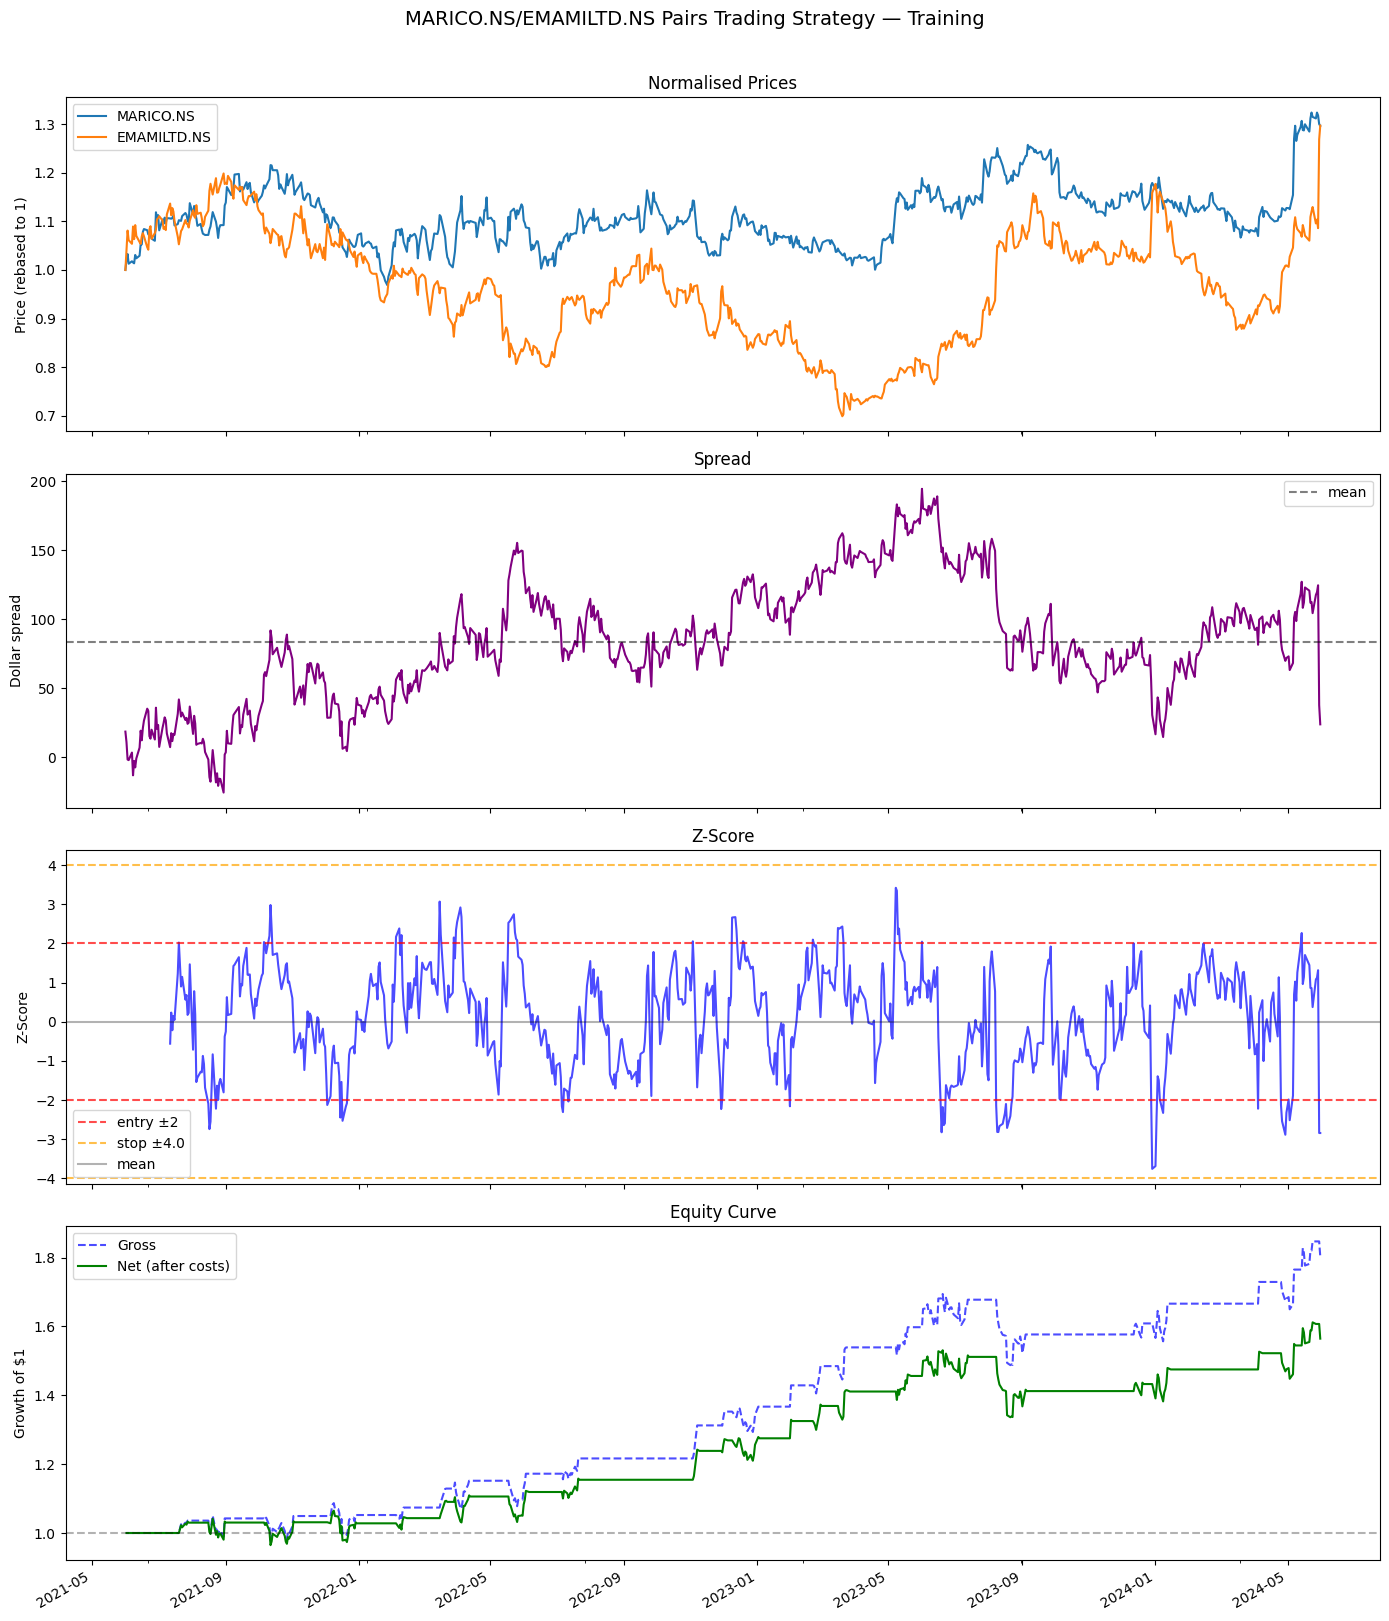


=== TEST RESULTS ===
Sharpe:       0.45
Max Drawdown: -25.09%
Total Return: 14.82%
Total Trades: 37
Win Rate:     46.61%


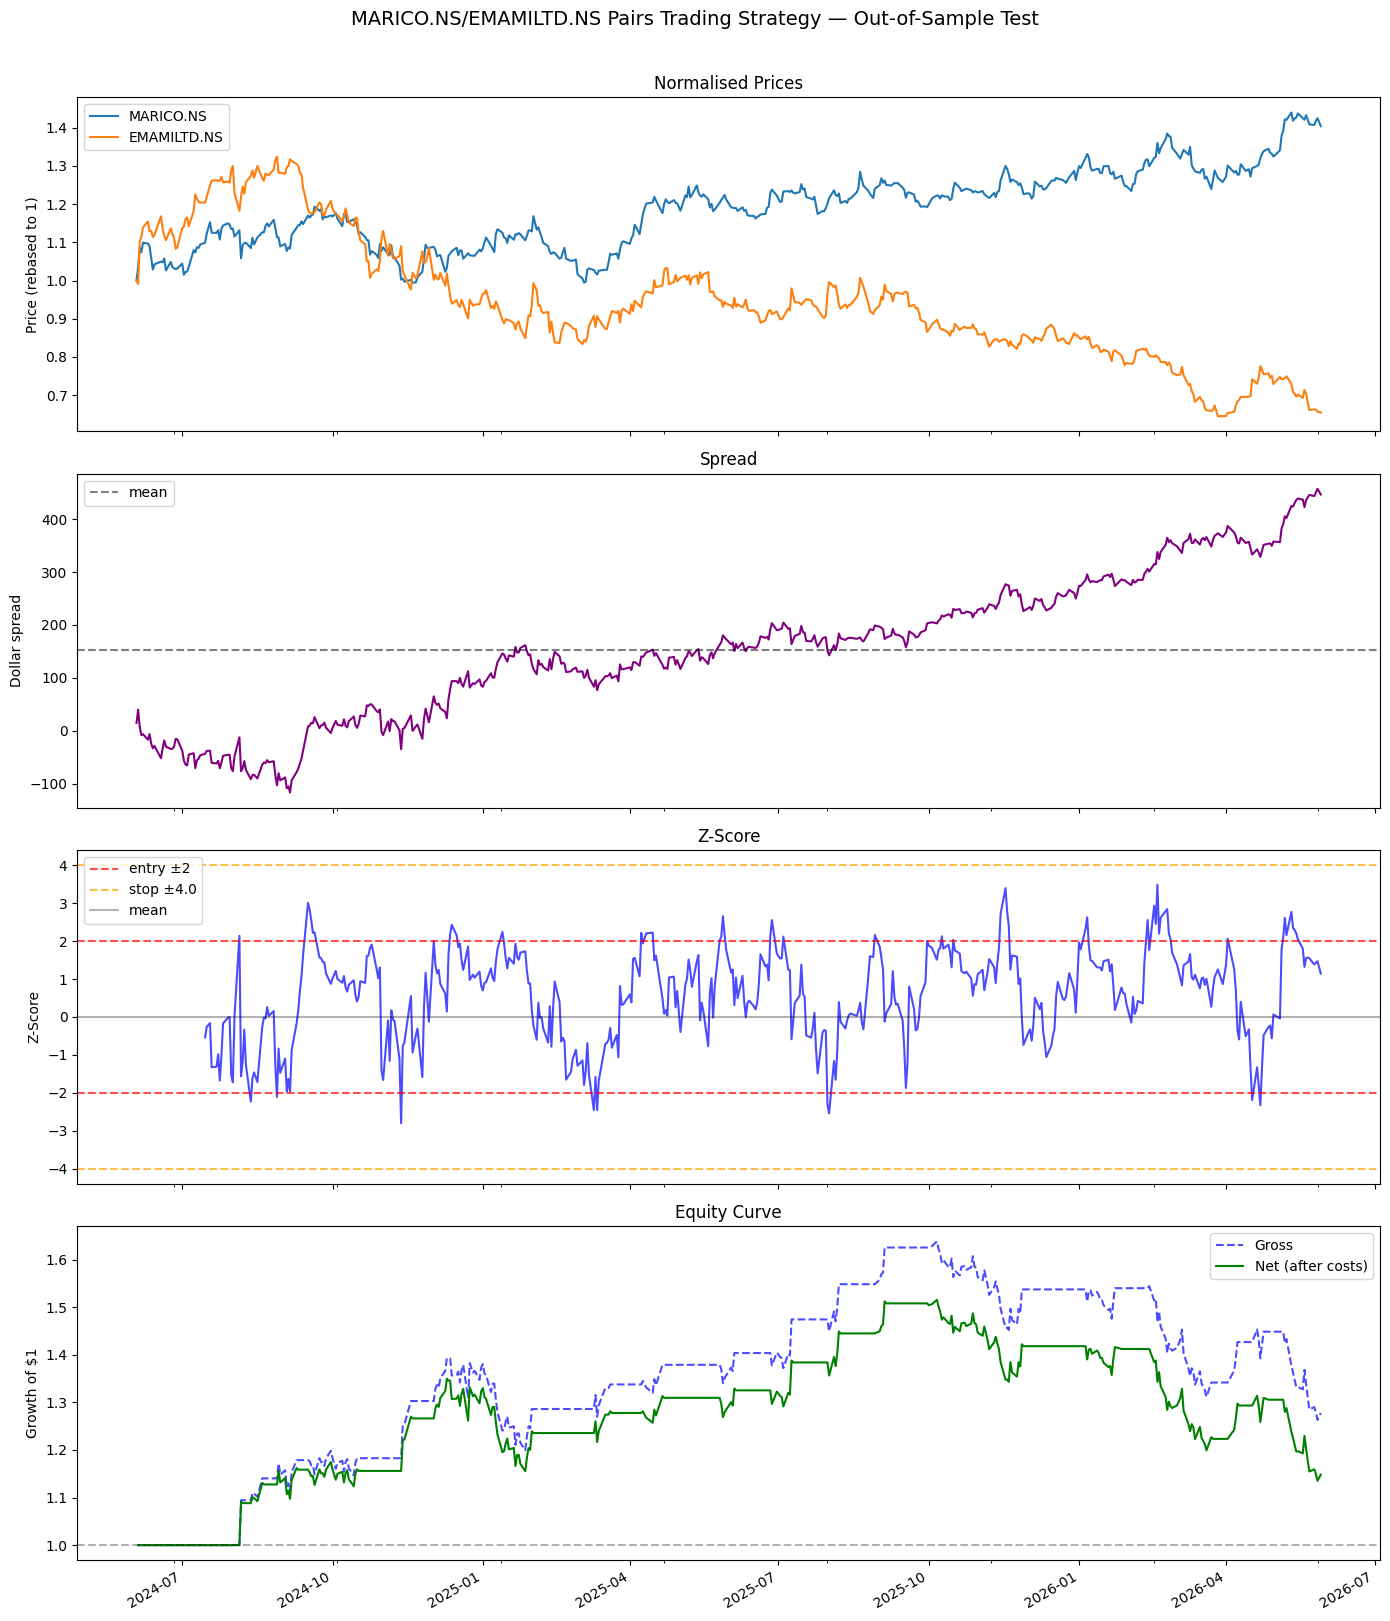

In [13]:

# --- TRAINING ---
train_res = run_backtest(closed_df, stock_a, stock_b,hedge_ratio=hedge_ratio, stop =4.0)

print("=== TRAINING RESULTS ===")
print(f"Sharpe:       {train_res['sharpe']:.2f}")
print(f"Max Drawdown: {train_res['max_drawdown']:.2%}")
print(f"Total Return: {train_res['total_return']:.2%}")
print(f"Total Trades: {train_res['trades']}")
print(f"Win Rate:     {train_res['win_rate']:.2%}")

plot_results(closed_df, stock_a, stock_b,
             train_res['zscore'],
             train_res['equity_gross'],
             train_res['equity_net'],
             hedge_ratio=train_res['hedge_ratio'],
             title_suffix="Training")

# --- TEST ---
test_res = run_backtest(closed_df_test, stock_a, stock_b, 
                         hedge_ratio=hedge_ratio,stop =4.0)

print("\n=== TEST RESULTS ===")
print(f"Sharpe:       {test_res['sharpe']:.2f}")
print(f"Max Drawdown: {test_res['max_drawdown']:.2%}")
print(f"Total Return: {test_res['total_return']:.2%}")
print(f"Total Trades: {test_res['trades']}")
print(f"Win Rate:     {test_res['win_rate']:.2%}")

plot_results(closed_df_test, stock_a, stock_b,
             test_res['zscore'],
             test_res['equity_gross'],
             test_res['equity_net'],
             hedge_ratio=test_res['hedge_ratio'],
             title_suffix="Out-of-Sample Test")

In [14]:
print("=" * 45)
print(f"{'Metric':<20} {'Training':>10} {'Test':>10}")
print("=" * 45)
print(f"{'Sharpe Ratio':<20} {train_res['sharpe']:>10.2f} {test_res['sharpe']:>10.2f}")
print(f"{'Max Drawdown':<20} {train_res['max_drawdown']:>10.2%} {test_res['max_drawdown']:>10.2%}")
print(f"{'Total Return':<20} {train_res['total_return']:>10.2%} {test_res['total_return']:>10.2%}")
print(f"{'Total Trades':<20} {train_res['trades']:>10} {test_res['trades']:>10}")
print(f"{'Win Rate':<20} {train_res['win_rate']:>10.2%} {test_res['win_rate']:>10.2%}")
print("=" * 45)

Metric                 Training       Test
Sharpe Ratio               1.00       0.45
Max Drawdown            -12.71%    -25.09%
Total Return             56.47%     14.82%
Total Trades                 49         37
Win Rate                 46.84%     46.61%
